# 04 · CART và SVM tự cài — TV2
CART tối ưu Gini; SVM tuyến tính squared hinge, L2, bias được regularize như cột hằng. Chuẩn hóa fit trên train.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sar_oil import core, reference
from sar_oil.data import records, read_pair, MANIFEST
from sar_oil.experiments import OUT
def table(rows, columns):
    def value(x): return (f'{x:.3e}' if 0<abs(x)<1e-4 else f'{x:.6f}') if isinstance(x,float) else str(x)
    display(HTML('<table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in rows)+'</table>'))
def load(name):
    p=OUT/name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Run python scripts/sos.py reproduce first.')
    return json.loads(p.read_text(encoding='utf-8'))


Ứng viên train có purity >=0.5 là dầu, <=0.05 là nền; phần còn lại bỏ khỏi train, vẫn tính đầy đủ khi đánh giá. Tối đa 10.000 vùng mỗi lớp, seed 2026. SVM tối ưu cùng mục tiêu với LinearSVC: (0.5||w||² + C∑max(1−y·Xw,0)²)/n. CART có thể khác tie-break/precision của sklearn; báo agreement và F1 thực tế.

kind,group,params,agreement,converged,numpy_f1,reference_f1
cart,all,"{'max_depth': 3, 'min_leaf': 20}",1.000000,True,0.337252,0.337252
svm,all,{'C': 10},1.000000,True,0.340312,0.340312


{'objective': 4.053122885874714, 'reference_objective': 4.053122885871837, 'gradient_max': 9.942896410500638e-07, 'iterations': 177}
cart timing: {'numpy_fit_seconds': 0.21444830000018555, 'reference_fit_seconds': 0.11586669999996957} candidate confusion: {'numpy': {'tp': 2112, 'fp': 544, 'tn': 6008, 'fn': 623}, 'reference': {'tp': 2112, 'fp': 544, 'tn': 6008, 'fn': 623}}
svm timing: {'numpy_fit_seconds': 0.27651650000007066, 'reference_fit_seconds': 0.06504289999975299} candidate confusion: {'numpy': {'tp': 2266, 'fp': 612, 'tn': 5940, 'fn': 469}, 'reference': {'tp': 2266, 'fp': 612, 'tn': 5940, 'fn': 469}}


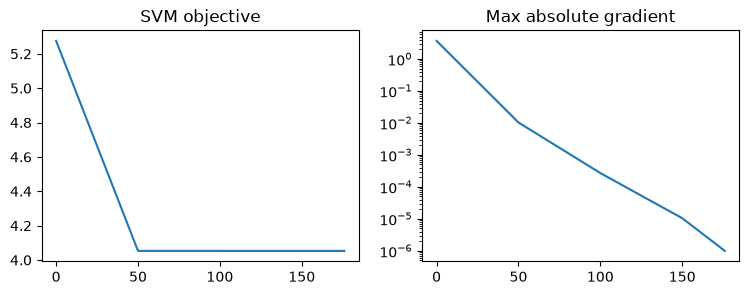

In [2]:
rows=load('model_comparison.json')
table([dict(kind=r['kind'],group=r['group'],params=str(r['params']),agreement=r['agreement'],converged=r['converged'],numpy_f1=r['metrics']['f1'],reference_f1=r['reference_metrics']['f1']) for r in rows],['kind','group','params','agreement','converged','numpy_f1','reference_f1'])
svm=next(r for r in rows if r['kind']=='svm')
print({k:svm[k] for k in ('objective','reference_objective','gradient_max','iterations')})
for row in rows:
    print(row['kind'],'timing:',row['timings'],'candidate confusion:',row['candidate_confusion'])
h=np.asarray(svm['history'])
if h[-1,0]!=svm['iterations']-1: h=np.vstack([h,[svm['iterations']-1,svm['objective'],svm['gradient_max']]])
fig,axes=plt.subplots(1,2,figsize=(9,3)); axes[0].plot(h[:,0],h[:,1]); axes[0].set_title('SVM objective'); axes[1].semilogy(h[:,0],h[:,2]); axes[1].set_title('Max absolute gradient'); plt.show()

In [3]:
from sar_oil.models import RegionModel
selected=load('selected.json'); model=RegionModel.load(OUT/selected['model_file'])
print('Cấu hình NumPy được chọn trên validation:',selected['kind'],selected['params'])
print('Kiểm chứng thuật toán:',load('verification.json')['passed'])
# Huấn luyện lại trên vùng train thật. Cache chỉ tiết kiệm bước trích đặc trưng.
from sar_oil.experiments import region_data, training_arrays, GROUPS
X,y,training=training_arrays(region_data(selected['config'],'train',workers=1))
retrained=RegionModel(selected['kind'],GROUPS[selected['group']],**selected['params']).fit(X,y)
reference_model=RegionModel(selected['kind'],GROUPS[selected['group']],backend='reference',**selected['params']).fit(X,y)
print('Số vùng train:',training)
print('Agreement trên train (không phải test):',np.mean(retrained.predict(X)==reference_model.predict(X)))
assert retrained.converged
assert np.array_equal(retrained.predict(X),model.predict(X))

Cấu hình NumPy được chọn trên validation: svm {'C': 10}
Kiểm chứng thuật toán: True


Số vùng train: {'positive': 11092, 'negative': 25946, 'ambiguous': 2492, 'used': 20000}
Agreement trên train (không phải test): 1.0
